# Vlastní experimenty 1: slice sampling vs. Random Walk Metropolis v 1D

Tento notebook navazuje na `motivation.ipynb` a nabízí možnosti, jak postupovat v první fázi práce: vlastní implementace obou metod, diagnostika MCMC a první systematické srovnání. Není to pevné zadání – pokud máte vlastní nápad, jak něco otestovat, klidně se od něj odchylte; podstatné je, aby každý experiment končil **tabulkou nebo grafem a krátkým písemným závěrem** (několik vět opřených o konkrétní čísla), protože přesně z takových závěrů se později skládá praktická část práce.

**Doporučení**
- Kód v experimentech 1, 2, 4 a 6 zkuste napsat **bez nahlížení do `samplers.py`** (po dokončení si ho s referencí porovnejte).
- Všude používejte seedovaný generátor `np.random.default_rng(seed)`, aby šly výsledky zopakovat.
- Srovnáváme **počtem vyhodnocení cílové hustoty**, ne časem.
- Co nestihnete, nechte být – lepší tři dokončené experimenty se závěry než šest rozpracovaných.

**Literatura:** 
- Neal (2003), Single-variable slice sampling, procedury "stepping-out", "doubling", "shrinkage" - kapitola 4 od začátku po sekci 4.2 včetně
https://www.jstor.org/stable/pdf/3448413.pdf
- Robert & Casella (2004), RWMH algoritmus - sekce 7.5
https://mcube.lab.nycu.edu.tw/~cfung/docs/books/robert2004monte_carlo_statistical_methods.pdf
- k odhadu autokorelačního času Foreman-Mackey et al. (2013), *emcee: The MCMC Hammer* - doporučuji tutoriál
https://emcee.readthedocs.io/en/stable/tutorials/autocorr/
(případně článek https://arxiv.org/pdf/1202.3665)



In [6]:
import numpy as np
import matplotlib.pyplot as plt
from samplers import slice_sampling, metropolis_hastings   # referenční implementace (jen pro kontrolu a pro experimenty 3 a 5)

SQRT_2PI = np.sqrt(2 * np.pi)

def normal_pdf(x, mu, sigma):
    return np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * SQRT_2PI)

def make_mixture(m=2.0):
    """Směs 0,3·N(-m, 1²) + 0,7·N(m, 0,7²); m řídí vzdálenost módů. Pro m=2 jde o rozdělení z motivace.
    Vrací (log_pdf, true_mean, true_sd, true_P_left), kde true_P_left = P(x < 0)."""
    from math import erf, sqrt
    Phi = lambda z: 0.5 * (1 + erf(z / sqrt(2)))
    def log_pdf(x):
        p = 0.3 * normal_pdf(x, -m, 1.0) + 0.7 * normal_pdf(x, m, 0.7)
        return np.log(p) if p > 0 else -np.inf
    mean = 0.3 * (-m) + 0.7 * m
    var = 0.3 * (1 + m**2) + 0.7 * (0.49 + m**2) - mean**2
    p_left = 0.3 * Phi(m / 1.0) + 0.7 * Phi(-m / 0.7)
    return log_pdf, mean, np.sqrt(var), p_left

def log_std_normal(x):
    return -0.5 * x**2

def iact_ref(x, c=5.0, max_lag=None):
    """Referenční integrovaný autokorelační čas tau = 1 + 2 * sum_{T>=1} rho(T)
    (Foreman-Mackey et al. 2013, rov. (12)-(13)). Součet je useknut Sokalovým automatickým oknem,
    jak je implementováno v balíku acor / emcee (Goodman & Weare 2010): vezme se nejmenší M,
    pro které M >= c * tau(M), kde tau(M) = 1 + 2 * sum_{T=1}^{M} rho(T); výchozí c = 5.
    Použijte jen pro kontrolu vlastní implementace v experimentu 2."""
    x = np.asarray(x, dtype=float) - np.mean(x)
    n = len(x)
    max_lag = max_lag or n // 2
    f = np.fft.rfft(x, 2 * n)
    rho = np.fft.irfft(f * np.conj(f))[:max_lag]
    rho = rho / rho[0]
    taus = 1.0 + 2.0 * np.cumsum(rho[1:])          # taus[M-1] = tau(M)
    M = np.arange(1, len(taus) + 1)
    ok = np.nonzero(M >= c * taus)[0]
    if len(ok) == 0:
        return taus[-1]                               # okno se nenašlo – řetězec je příliš krátký vzhledem k tau
    return taus[ok[0]]

def print_table(headers, rows, fmt=None):
    """Vytiskne tabulku v Markdown syntaxi (lze zkopírovat do textu práce)."""
    fmt = fmt or ["{}"] * len(headers)
    print("| " + " | ".join(headers) + " |")
    print("|" + "---|" * len(headers))
    for r in rows:
        print("| " + " | ".join(f.format(v) for f, v in zip(fmt, r)) + " |")

log_mix, MIX_MEAN, MIX_SD, MIX_P_LEFT = make_mixture(2.0)
print(f"Směs z motivace: E[x] = {MIX_MEAN:.4f}, sd = {MIX_SD:.4f}, P(x<0) = {MIX_P_LEFT:.4f}  (pozor: není to 0,3 – komponenty se překrývají)")

Směs z motivace: E[x] = 0.8000, sd = 2.0007, P(x<0) = 0.2947  (pozor: není to 0,3 – komponenty se překrývají)


---
## Experiment 1 – Vlastní implementace a test správnosti

Naprogramujte vlastní **Random Walk Metropolis** a **1D slice sampling se stepping-out a shrinking** (Neal 2003, obr. 3 a 5). Obě funkce vracejí pole vzorků a **celkový počet vyhodnocení `log_pdf`** – počítejte každé volání, včetně testů ve stepping-out.

Správnost ověřte na dvou rozděleních: $\mathcal N(0,1)$ a směsi z motivace. Pro každou kombinaci (rozdělení × metoda) spočítejte střední hodnotu, směrodatnou odchylku a $P(x<0)$ a porovnejte s přesnými hodnotami. Odhad je v pořádku, je-li odchylka do cca $3\times$ Monte Carlo chyby; tu zatím hrubě odhadněte jako $\mathrm{sd}/\sqrt{n/20}$ (v experimentu 2 ji spočítáte pořádně přes ESS).

In [7]:
def my_rwm(log_pdf, x0, n_samples, sigma, rng):
    """Random Walk Metropolis s návrhem x' = x + N(0, sigma²).
    Vrací (samples, accept_rate, n_evals)."""

    samples = []
    x = x0

    log_p = log_pdf(x)
    n_evals = 1
    accepted = 0

    for i in range(n_samples):
        # Navrh nove hodnoty
        x_new = x + rng.normal(0, sigma)

        # Logaritmus hustoty v novem bode
        log_p_new = log_pdf(x_new)
        n_evals += 1

        # Rozhodnuti o prijeti navrhu
        log_alpha = min(0, log_p_new - log_p)

        if np.log(rng.random()) < log_alpha:
            x = x_new
            log_p = log_p_new
            accepted += 1

        samples.append(x)

    accept_rate = accepted / n_samples

    return np.array(samples), accept_rate, n_evals

    # TODO: implementujte; nezapomeňte uchovávat log_pdf(x) aktuálního bodu (1 vyhodnocení na krok)
    raise NotImplementedError("Experiment 1: my_rwm")


def my_slice(log_pdf, x0, n_samples, w, rng):
    """1D slice sampling, stepping-out + shrinking (Neal 2003, Fig. 3 a 5), bez omezení počtu kroků m.
    Vrací (samples, n_evals)."""

    samples = []
    x = x0

    log_p = log_pdf(x)
    n_evals = 1

    for i in range(n_samples):

        # 1. Nahodna vyska rezu
        log_y = log_p + np.log(rng.random())

        # 2. Pocatecni interval
        u = rng.random()
        L = x - w * u
        R = L + w

        # 3. Stepping-out doleva
        while True:
            n_evals += 1
            if log_pdf(L) <= log_y:
                break
            L -= w

        # 4. Stepping-out doprava
        while True:
            n_evals += 1
            if log_pdf(R) <= log_y:
                break
            R += w

        # 5. Shrinking
        while True:
            x_new = rng.uniform(L, R)

            log_p_new = log_pdf(x_new)
            n_evals += 1

            if log_p_new >= log_y:
                x = x_new
                log_p = log_p_new
                break

            if x_new < x:
                L = x_new
            else:
                R = x_new

        samples.append(x)

    return np.array(samples), n_evals

    # TODO: implementujte; počítejte každé vyhodnocení log_pdf
    raise NotImplementedError("Experiment 1: my_slice")

In [8]:
N, BURN = 20_000, 1_000
targets = {
    "N(0,1)": (log_std_normal, 0.0, 1.0, 0.5),
    "směs":   (log_mix, MIX_MEAN, MIX_SD, MIX_P_LEFT),
}
rows = []
for name, (lp, m_true, sd_true, pl_true) in targets.items():
    s_r, acc, ne_r = my_rwm(lp, x0=0.0, n_samples=N, sigma=2.0, rng=np.random.default_rng(1))
    s_s, ne_s = my_slice(lp, x0=0.0, n_samples=N, w=2.0, rng=np.random.default_rng(1))
    for meth, s, ne in [("RWM σ=2", s_r[BURN:], ne_r), ("slice w=2", s_s[BURN:], ne_s)]:
        mc_err = s.std() / np.sqrt(len(s) / 20)
        rows.append([name, meth, s.mean(), m_true, s.std(), sd_true, np.mean(s < 0), pl_true, mc_err, ne / N])

print_table(["rozdělení", "metoda", "E[x] odhad", "E[x] přesně", "sd odhad", "sd přesně", "P(x<0) odhad", "P(x<0) přesně", "~MC chyba E[x]", "vyhodnocení / vzorek"],
            rows, ["{}", "{}", "{:.4f}", "{:.4f}", "{:.4f}", "{:.4f}", "{:.4f}", "{:.4f}", "{:.4f}", "{:.1f}"])

| rozdělení | metoda | E[x] odhad | E[x] přesně | sd odhad | sd přesně | P(x<0) odhad | P(x<0) přesně | ~MC chyba E[x] | vyhodnocení / vzorek |
|---|---|---|---|---|---|---|---|---|---|
| N(0,1) | RWM σ=2 | -0.0117 | 0.0000 | 0.9976 | 1.0000 | 0.5040 | 0.5000 | 0.0324 | 1.0 |
| N(0,1) | slice w=2 | -0.0024 | 0.0000 | 1.0080 | 1.0000 | 0.5007 | 0.5000 | 0.0327 | 5.2 |
| směs | RWM σ=2 | 0.7432 | 0.8000 | 2.0214 | 2.0007 | 0.3044 | 0.2947 | 0.0656 | 1.0 |
| směs | slice w=2 | 0.8287 | 0.8000 | 1.9835 | 2.0007 | 0.2894 | 0.2947 | 0.0644 | 5.6 |


In [9]:

# Porovnani vlastni a referencni implementace Slice Samplingu

N = 20000
w = 2.0
seed = 42

# Nase implementace
samples_my, evals_my = my_slice(
    log_std_normal,
    x0=0.0,
    n_samples=N,
    w=w,
    rng=np.random.default_rng(seed)
)

# Referencni implementace
samples_ref, evals_ref = slice_sampling(
    log_std_normal,
    x0=0.0,
    n_samples=N,
    w=w,
    rng=np.random.default_rng(seed)
)

print("                 Nase       Reference")
print("Prumer:        ", round(np.mean(samples_my), 4),
      round(np.mean(samples_ref), 4))
print("Smer. odch.:   ", round(np.std(samples_my), 4),
      round(np.std(samples_ref), 4))
print("P(X < 0):      ", round(np.mean(samples_my < 0), 4),
      round(np.mean(samples_ref < 0), 4))
print("Vyhodnoceni:   ", evals_my, evals_ref)
print("Na vzorek:     ", round(evals_my / N, 2),
      round(evals_ref / N, 2))


                 Nase       Reference
Prumer:         0.0032 0.0032
Smer. odch.:    0.996 0.996
P(X < 0):       0.4976 0.4976
Vyhodnoceni:    103887 123886
Na vzorek:      5.19 6.19


**Kontrola proti referenci:** po dokončení spusťte totéž s `metropolis_hastings` a `slice_sampling` ze `samplers.py` (stejný seed) a porovnejte počty vyhodnocení na vzorek. Shodují se? Pokud ne, kde se vaše implementace liší (např. počítání testů ve stepping-out)?

**Závěr k experimentu 1** *(doplňte)*: Jsou obě implementace správné? Kolik vyhodnocení $f$ stojí jeden vzorek u každé metody a odkud se ten rozdíl bere?

> 

Obě implementace poskytují odhady střední hodnoty, směrodatné odchylky a pravděpodobnosti P(X < 0), které jsou blízké teoretickým hodnotám pro standardní normální rozdělení i směs dvou normálních rozdělení.

Metoda Random Walk Metropolis potřebovala přibližně 1 vyhodnocení logaritmické hustoty na jeden vzorek, zatímco Slice Sampling přibližně 5,2 až 5,6 vyhodnocení na vzorek.

Vyšší počet vyhodnocení u Slice Samplingu je způsoben rozšiřováním intervalu (stepping-out) a jeho případným zužováním (shrinking).

Výsledky naznačují, že obě implementace fungují správně. Pro důkladnější ověření je však vhodné porovnat je také s referenčními implementacemi a posoudit autokorelaci a efektivní počet vzorků (ESS).

---
## Experiment 2 – Autokorelace, IACT a efektivní počet vzorků

Vzorky MCMC jsou závislé, proto $n$ vzorků neodpovídá $n$ nezávislým. Implementujte:

1. `acf(x, max_lag)` – výběrovou autokorelační funkci $\rho_k = C(k)/C(0)$ pro $k = 0,\dots,$ `max_lag`, kde $C(k)$ je výběrová autokovariance podle rov. (13) ve Foreman-Mackey et al. (2013) (nebo ekvivalentně přes FFT),
2. `iact(x)` – integrovaný autokorelační čas $\tau = 1 + 2\sum_{k\ge 1}\rho_k$ (rov. (12) tamtéž). Součet je nutné někde useknout, jinak ho přehluší šum odhadu $\rho_k$ pro velká $k$. Použijte Sokalovo automatické okno, které používá balík acor/emcee (Goodman & Weare 2010): spočítejte $\tau(M) = 1 + 2\sum_{k=1}^{M}\rho_k$ a vezměte nejmenší $M$, pro něž $M \ge c\,\tau(M)$, s $c = 5$,
3. $\mathrm{ESS} = n/\tau$ a Monte Carlo chybu střední hodnoty $\mathrm{sd}/\sqrt{\mathrm{ESS}}$.

Výsledek ověřte proti `iact_ref` (mělo by vyjít prakticky totéž) a volitelně proti `emcee.autocorr.integrated_time`, která implementuje stejné pravidlo. Rozmyslete, proč je potřeba řetězec aspoň $\sim 50\,\tau$ dlouhý, aby odhad dával smysl.

In [10]:
def acf(x, max_lag=200):
    """Výběrová autokorelace rho_k, k = 0..max_lag. Vrací pole délky max_lag+1."""
    # TODO
    x = np.asarray(x, dtype=float)
    N = len(x)
    mu = x.mean()                     
    d = x - mu                        #  d_i = x_i - mu

    c = np.zeros(max_lag + 1)         # c[k] = C(k)
    for k in range(max_lag + 1):
        # sum d_i * d_(i+k) pro i = 0 ... N-k-1, делим на N-k  (f 13)
        c[k] = np.sum(d[:N - k] * d[k:]) / (N - k)

    rho = c / c[0]                    # rho_k = C(k) / C(0)
    return rho
    raise NotImplementedError("Experiment 2: acf")


def iact(x, max_lag=None, c=5.0):
    """Integrovaný autokorelační čas tau = 1 + 2 * sum_{k>=1} rho_k, useknutý Sokalovým oknem (M >= c * tau(M), c = 5).
    max_lag=None znamená len(x) // 2."""
    #
    N = len(x)
    if max_lag is None:
        max_lag = N // 2
    rho = acf(x, max_lag)

    suma = 0.0                        # rho_1 + ... + rho_M
    for M in range(1, max_lag + 1):
        suma += rho[M]
        tau_M = 1 + 2 * suma          # tau(M)
        if M >= c * tau_M:            # Sokalovo okno
            return tau_M
    return tau_M        
    raise NotImplementedError("Experiment 2: iact")


def ess(x):
    return len(x) / iact(x)

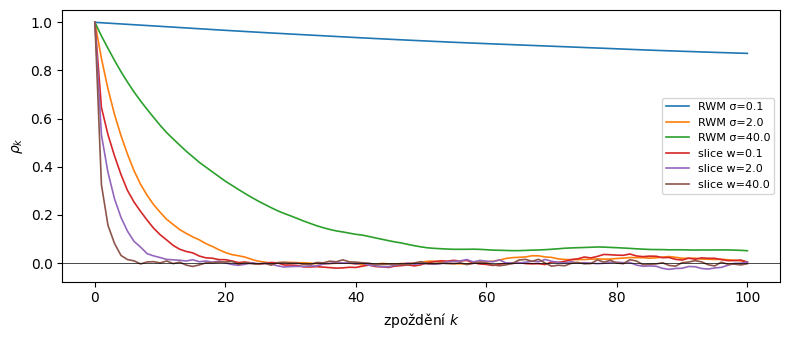

| běh | IACT (vlastní) | IACT (reference) | ESS | MC chyba E[x] | vyhodnocení / vzorek |
|---|---|---|---|---|---|
| RWM σ=0.1 | 1189.0 | 1224.9 | 16 | 0.4285 | 1.0 |
| RWM σ=2.0 | 12.7 | 12.7 | 1499 | 0.0507 | 1.0 |
| RWM σ=40.0 | 37.9 | 38.0 | 501 | 0.0826 | 1.0 |
| slice w=0.1 | 7.9 | 7.9 | 2408 | 0.0402 | 35.2 |
| slice w=2.0 | 4.6 | 4.6 | 4103 | 0.0305 | 5.6 |
| slice w=40.0 | 2.3 | 2.3 | 8385 | 0.0218 | 6.7 |


In [11]:
# Graf ACF a tabulka IACT/ESS pro RWM (σ = 0,1; 2; 40) a slice (w = 0,1; 2; 40) na směsi z motivace
N, BURN = 20_000, 1_000
runs = []
for sigma in [0.1, 2.0, 40.0]:
    s, acc, ne = my_rwm(log_mix, 0.0, N, sigma, np.random.default_rng(0))
    runs.append((f"RWM σ={sigma}", s[BURN:], ne))
for w in [0.1, 2.0, 40.0]:
    s, ne = my_slice(log_mix, 0.0, N, w, np.random.default_rng(0))
    runs.append((f"slice w={w}", s[BURN:], ne))

fig, ax = plt.subplots(figsize=(8, 3.5))
for name, s, ne in runs:
    ax.plot(acf(s, 100), label=name, lw=1.2)
ax.axhline(0, color="k", lw=0.5); ax.set_xlabel("zpoždění $k$"); ax.set_ylabel(r"$\rho_k$"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

rows = []
for name, s, ne in runs:
    tau = iact(s)
    rows.append([name, tau, iact_ref(s), len(s) / tau, s.std() / np.sqrt(len(s) / tau), ne / N])
print_table(["běh", "IACT (vlastní)", "IACT (reference)", "ESS", "MC chyba E[x]", "vyhodnocení / vzorek"],
            rows, ["{}", "{:.1f}", "{:.1f}", "{:.0f}", "{:.4f}", "{:.1f}"])

**Závěr k experimentu 2** *(doplňte)*: Jak moc se liší $n$ a ESS? Který běh má nejhorší míchání a jak to vypadá na ACF? Vraťte se k tabulce z experimentu 1 – byla hrubá MC chyba $\mathrm{sd}/\sqrt{n/20}$ přiměřená?

> n = 19 000, ale ESS je jen 16 až 8385 (0,08 % až 44 % z n); největší rozdíl je u RWM s σ=0,1 (τ ≈ 1200). Nejhorší míchání má právě RWM σ=0,1: ACF klesá velmi pomalu (při k=100 je ρ ≈ 0,9), protože řetězec dělá příliš malé kroky; nejlepší je slice s w=40, jehož ACF klesne k nule během několika kroků. Hrubá MC chyba sd/√(n/20) ≈ 0,065 předpokládala τ=20 pro všechny běhy, proto byla přiměřená jen pro RWM σ=2 (skutečná chyba 0,051); u σ=0,1 byla podhodnocena zhruba 7×, u slice nadhodnocena 1,6–3×, takže τ je nutné odhadovat z dat. U σ=0,1 je řetězec kratší než 50τ, proto je τ jen dolní odhad (vlastní a referenční hodnota se tam liší: 1189 vs 1225).

---
## Experiment 3 – Citlivost na volbu parametru (kritérium 1 ze zadání)

Pro směs z motivace projděte $\sigma$ (RWM) i $w$ (slice) na **logaritmické mřížce** `np.logspace(-1.5, 2.5, 9)` (≈ 0,03 až 300). Pro každou hodnotu spočítejte

- ESS na 1000 vyhodnocení $f$: $\;1000\cdot \mathrm{ESS}/(\text{počet vyhodnocení})$,
- počet přechodů mezi módy (změn znaménka $x$) na 1000 vzorků.

Vykreslete ESS/1000 vyhodnocení jako funkci parametru (log osa $x$) pro obě metody do jednoho grafu a vyplňte tabulku. **Robustnost** kvantifikujte jako šířku rozsahu parametru (v řádech, tj. $\log_{10}(\text{max}/\text{min})$), ve kterém metoda dosahuje alespoň 50 % svého maxima ESS/vyhodnocení.

Zde můžete použít vlastní samplery z experimentu 1, nebo referenční ze `samplers.py` – uveďte které.

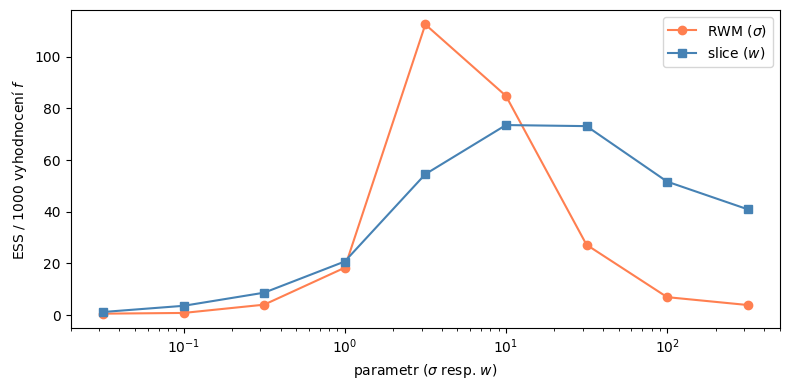

RWM
| σ | akceptace | ESS/1000 vyh. | přechody/1000 vz. | vyhodnocení/vzorek |
|---|---|---|---|---|
| 0.0316 | 0.99 | 0.6 | 1.3 | 1.0 |
| 0.1 | 0.96 | 0.8 | 1.6 | 1.0 |
| 0.316 | 0.87 | 4.0 | 6.4 | 1.0 |
| 1 | 0.66 | 18.3 | 28.4 | 1.0 |
| 3.16 | 0.40 | 112.5 | 110.0 | 1.0 |
| 10 | 0.17 | 84.9 | 68.3 | 1.0 |
| 31.6 | 0.05 | 27.2 | 24.5 | 1.0 |
| 100 | 0.02 | 7.0 | 6.9 | 1.0 |
| 316 | 0.01 | 3.9 | 2.3 | 1.0 |

slice
| w | – | ESS/1000 vyh. | přechody/1000 vz. | vyhodnocení/vzorek |
|---|---|---|---|---|
| 0.0316 | nan | 1.2 | 88.7 | 104.5 |
| 0.1 | nan | 3.6 | 88.2 | 35.2 |
| 0.316 | nan | 8.7 | 95.5 | 13.6 |
| 1 | nan | 20.8 | 114.8 | 6.8 |
| 3.16 | nan | 54.6 | 187.6 | 5.2 |
| 10 | nan | 73.6 | 239.5 | 5.3 |
| 31.6 | nan | 73.2 | 254.7 | 6.4 |
| 100 | nan | 51.7 | 256.9 | 8.2 |
| 316 | nan | 41.0 | 260.4 | 10.2 |
RWM  : max ESS/1000 vyh. = 112.5; ≥50 % maxima pro parametr v [3.16, 10] → šířka 0.5 řádu
slice: max ESS/1000 vyh. = 73.6; ≥50 % maxima pro parametr v [3.16, 316] → šířka 2.0

In [12]:
grid = np.logspace(-1.5, 2.5, 9)
N, BURN = 20_000, 1_000

def evaluate_run(samples, n_evals, n_total):
    """Vrací (ESS na 1000 vyhodnocení, přechody mezi módy na 1000 vzorků)."""
    s = samples[BURN:]
    e = len(s) / iact(s)
    switches = np.sum(np.diff(s < 0) != 0)
    return 1000 * e / (n_evals * len(s) / n_total), 1000 * switches / len(s)

res_rwm, res_slice = [], []
for p in grid:
    s, acc, ne = my_rwm(log_mix, 0.0, N, p, np.random.default_rng(0))      # nebo metropolis_hastings(log_mix, 0.0, N, proposal_std=p, rng=...)
    res_rwm.append((p, acc, *evaluate_run(s, ne, N), ne / N))
    s, ne = my_slice(log_mix, 0.0, N, p, np.random.default_rng(0))          # nebo slice_sampling(log_mix, 0.0, N, w=p, rng=...)
    res_slice.append((p, np.nan, *evaluate_run(s, ne, N), ne / N))

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(grid, [r[2] for r in res_rwm], "o-", color="coral", label="RWM ($\\sigma$)")
ax.semilogx(grid, [r[2] for r in res_slice], "s-", color="steelblue", label="slice ($w$)")
ax.set_xlabel("parametr ($\\sigma$ resp. $w$)"); ax.set_ylabel("ESS / 1000 vyhodnocení $f$"); ax.legend()
plt.tight_layout(); plt.show()

print("RWM"); print_table(["σ", "akceptace", "ESS/1000 vyh.", "přechody/1000 vz.", "vyhodnocení/vzorek"], res_rwm, ["{:.3g}", "{:.2f}", "{:.1f}", "{:.1f}", "{:.1f}"])
print("\nslice"); print_table(["w", "–", "ESS/1000 vyh.", "přechody/1000 vz.", "vyhodnocení/vzorek"], res_slice, ["{:.3g}", "{}", "{:.1f}", "{:.1f}", "{:.1f}"])

def robust_range(params, eff, frac=0.5):
    """Šířka (v řádech) rozsahu parametru, kde eff >= frac * max(eff)."""
    ok = np.asarray(eff) >= frac * np.max(eff)
    p = np.asarray(params)[ok]
    return np.log10(p.max() / p.min()), p.min(), p.max()

for name, res in [("RWM", res_rwm), ("slice", res_slice)]:
    width, lo, hi = robust_range([r[0] for r in res], [r[2] for r in res])
    print(f"{name:5}: max ESS/1000 vyh. = {max(r[2] for r in res):.1f}; ≥50 % maxima pro parametr v [{lo:.3g}, {hi:.3g}] → šířka {width:.1f} řádu")

**Závěr k experimentu 3** *(doplňte)*: Která metoda má vyšší maximum ESS na vyhodnocení a o kolik? Která má širší „bezpečný“ rozsah parametru? Jak byste jednou větou formulovali kompromis mezi oběma metodami pro někoho, kdo nemá čas ladit? Souvisí akceptační poměr RWM s jeho maximem (srov. Roberts & Rosenthal 2001: optimum ≈ 0,44 v 1D)?

>Použila jsem vlastní implementace z experimentu 1 (my_rwm, my_slice), N = 20 000 a jeden seed. Z grafu je vidět, že RWM má vyšší maximum: při σ ≈ 3,16 dostaneme 112,5 efektivních vzorků na 1000 vyhodnocení, kdežto slice má maximum 73,6 (pro w = 10), takže je asi o třetinu slabší. U RWM je ale maximum hodně úzké: aspoň polovinu maxima drží jen σ mezi 3,16 a 10, což je 0,5 řádu. Slice je na tom naopak: polovinu maxima má pro w od 3,16 až do 316, tedy aspoň 2 řády (je to dolní odhad, protože rozsah končí na kraji mřížky). U slice se špatné w projeví hlavně tím, že vzorek stojí víc vyhodnocení (třeba 104 při w = 0,03), kdežto u RWM při špatném σ řetězec skoro nehybně stojí nebo se plazí. Kdo nemá čas ladit, měl by tedy sáhnout po slice; kdo parametr naladí, je s RWM efektivnější. Maximum RWM vyšlo při akceptaci 0,40, což je blízko teoretickému optimu asi 0,44 (Roberts & Rosenthal). Všechno je z jednoho seedu a z hrubé mřížky (půl řádu), takže čísla berme spíš jako odhad řádu.

---
## Experiment 4 – Zbytečné vyhodnocení ve slice sampleru

V referenční implementaci `slice_sampling` (a možná i ve vaší) se na začátku každé iterace počítá `log_pdf(x)` aktuálního bodu, ačkoli tato hodnota je známa z posledního kroku shrinking (přijatý bod $x'$ má známé $\log f(x')$).

1. Ověřte to: změřte počet vyhodnocení na vzorek pro $w=2$ a odhadněte, kolik z toho je toto opakované vyhodnocení.
2. Upravte svou implementaci tak, aby hodnotu uchovávala, a změřte znovu.
3. Doplňte do tabulky, o kolik se změní ESS na 1000 vyhodnocení pro $w \in \{0{,}1;\ 2;\ 40\}$.

In [13]:
def my_slice_orig(log_pdf, x0, n_samples, w, rng):
    """1D slice sampling, stepping-out + shrinking (Neal 2003, Fig. 3 a 5), bez omezení počtu kroků m.
    Vrací (samples, n_evals)."""

    samples = []
    x = x0

    log_p = log_pdf(x)
    n_evals = 1

    for i in range(n_samples):

        log_p = log_pdf(x) ###       
        n_evals += 1       ###

        # 1. Nahodna vyska rezu
        log_y = log_p + np.log(rng.random())

        # 2. Pocatecni interval
        u = rng.random()
        L = x - w * u
        R = L + w

        # 3. Stepping-out doleva
        while True:
            n_evals += 1
            if log_pdf(L) <= log_y:
                break
            L -= w

        # 4. Stepping-out doprava
        while True:
            n_evals += 1
            if log_pdf(R) <= log_y:
                break
            R += w

        # 5. Shrinking
        while True:
            x_new = rng.uniform(L, R)

            log_p_new = log_pdf(x_new)
            n_evals += 1

            if log_p_new >= log_y:
                x = x_new
                log_p = log_p_new
                break

            if x_new < x:
                L = x_new
            else:
                R = x_new

        samples.append(x)

    return np.array(samples), n_evals

    # TODO: implementujte; počítejte každé vyhodnocení log_pdf
    raise NotImplementedError("Experiment 1: my_slice")

In [14]:
def my_slice_cached(log_pdf, x0, n_samples, w, rng):
    """Jako my_slice, ale log_pdf aktuálního bodu se nepočítá znovu v každé iteraci."""
    return my_slice(log_pdf, x0, n_samples, w, rng)
    raise NotImplementedError("Experiment 4: my_slice_cached")

rows = []
for w in [0.1, 2.0, 40.0]:
    s1, ne1 = my_slice_orig(log_mix, 0.0, N, w, np.random.default_rng(0))
    s2, ne2 = my_slice_cached(log_mix, 0.0, N, w, np.random.default_rng(0))
    rows.append([w, ne1 / N, ne2 / N, evaluate_run(s1, ne1, N)[0], evaluate_run(s2, ne2, N)[0]])
print_table(["w", "vyh./vzorek původní", "vyh./vzorek cache", "ESS/1000 vyh. původní", "ESS/1000 vyh. cache"],
            rows, ["{}", "{:.2f}", "{:.2f}", "{:.1f}", "{:.1f}"])

| w | vyh./vzorek původní | vyh./vzorek cache | ESS/1000 vyh. původní | ESS/1000 vyh. cache |
|---|---|---|---|---|
| 0.1 | 36.21 | 35.21 | 3.5 | 3.6 |
| 2.0 | 6.56 | 5.56 | 32.9 | 38.9 |
| 40.0 | 7.74 | 6.74 | 57.1 | 65.5 |


In [ ]:
rows = []
for w in [0.1, 2.0, 40.0]:
    s1, ne1 = my_slice_orig(log_mix, 0.0, N, w, np.random.default_rng(0))
    s2, ne2 = my_slice_cached(log_mix, 0.0, N, w, np.random.default_rng(0))
    print(f"w={w}: stejné vzorky? {np.array_equal(s1, s2)}")      
    rows.append([w, ne1 / N, ne2 / N, evaluate_run(s1, ne1, N)[0], evaluate_run(s2, ne2, N)[0]])
print_table(["w", "vyh./vzorek původní", "vyh./vzorek cache", "ESS/1000 vyh. původní", "ESS/1000 vyh. cache"],
            rows, ["{}", "{:.2f}", "{:.2f}", "{:.1f}", "{:.1f}"])  

w=0.1: stejné vzorky? True
w=2.0: stejné vzorky? True
w=40.0: stejné vzorky? True
| w | vyh./vzorek původní | vyh./vzorek cache | ESS/1000 vyh. původní | ESS/1000 vyh. cache |
|---|---|---|---|---|
| 0.1 | 36.21 | 35.21 | 3.5 | 3.6 |
| 2.0 | 6.56 | 5.56 | 32.9 | 38.9 |
| 40.0 | 7.74 | 6.74 | 57.1 | 65.5 |


**Závěr k experimentu 4** *(doplňte)*: Dávají obě verze při stejném seedu stejné vzorky? (Měly by – proč?) Jak velký je relativní zisk a pro které $w$ je největší? Mění to závěr experimentu 3?

>Obě verze dávají při stejném seedu úplně stejné vzorky, protože log_pdf je deterministická a zbytečné vyhodnocení nespotřebuje žádná náhodná čísla. Zbytečné vyhodnocení stojí přesně jedno vyhodnocení na vzorek (např. 6,56 → 5,56 při w = 2), takže relativní zisk je 1/(počet vyhodnocení na vzorek): asi 3 % pro w = 0,1, 18 % pro w = 2 a 15 % pro w = 40; největší je pro w = 2, kde je vzorek nejlevnější.V experimentu 3 jsem používala už verzi, která hodnotu uchovává. S verzí bez uchování by maximum slice vyšlo odhadem asi 62 místo 73,6, takže by RWM byl asi 1,8× lepší místo 1,5×, ale závěr se nemění: RWM má vyšší maximum, slice širší rozsah parametru.

---
## Experiment 5 – Multimodalita: vzdálenost módů (kritérium 3 ze zadání)

Funkce `make_mixture(m)` vrací směs $0{,}3\,\mathcal N(-m,1^2) + 0{,}7\,\mathcal N(m,0{,}7^2)$. Pro $m \in \{1, 2, 3, 4\}$ spusťte

- RWM s $\sigma$, které vyšlo nejlépe v experimentu 3,
- slice s $w = 2$ a s $w = 20$,

a do tabulky zapište: odhad $P(x<0)$ vs. přesná hodnota, přechody mezi módy na 1000 vzorků, ESS na 1000 vyhodnocení. Použijte delší řetězce (`N = 50_000`), u $m=4$ jsou přechody vzácné.

In [ ]:
N, BURN = 50_000, 2_000
SIGMA_BEST = 3.16   # TODO: dosaďte nejlepší σ z experimentu 3

def rwm_pair(*args):
    s, acc, ne = my_rwm(*args)
    return s, ne          # stejný tvar návratu jako my_slice

rows = []
for m in [1, 2, 3, 4]:
    lp, _, _, p_left = make_mixture(m)
    configs = [
        ("RWM σ=%.3g" % SIGMA_BEST, lambda: rwm_pair(lp, 0.0, N, SIGMA_BEST, np.random.default_rng(0))),
        ("slice w=2",  lambda: my_slice(lp, 0.0, N, 2.0, np.random.default_rng(0))),
        ("slice w=20", lambda: my_slice(lp, 0.0, N, 20.0, np.random.default_rng(0))),
    ]
    for name, run in configs:
        s, ne = run()
        eff, sw = evaluate_run(s, ne, N)
        rows.append([m, name, np.mean(s[BURN:] < 0), p_left, sw, eff])
print_table(["m", "metoda", "P(x<0) odhad", "P(x<0) přesně", "přechody/1000 vz.", "ESS/1000 vyh."],
            rows, ["{}", "{}", "{:.3f}", "{:.3f}", "{:.1f}", "{:.1f}"])

| m | metoda | P(x<0) odhad | P(x<0) přesně | přechody/1000 vz. | ESS/1000 vyh. |
|---|---|---|---|---|---|
| 1 | RWM σ=3.16 | 0.304 | 0.306 | 138.5 | 192.6 |
| 1 | slice w=2 | 0.307 | 0.306 | 331.1 | 133.7 |
| 1 | slice w=20 | 0.307 | 0.306 | 333.1 | 121.1 |
| 2 | RWM σ=3.16 | 0.295 | 0.295 | 112.2 | 116.1 |
| 2 | slice w=2 | 0.289 | 0.295 | 152.8 | 39.3 |
| 2 | slice w=20 | 0.298 | 0.295 | 251.8 | 70.0 |
| 3 | RWM σ=3.16 | 0.293 | 0.300 | 49.2 | 60.4 |
| 3 | slice w=2 | 0.317 | 0.300 | 17.8 | 3.4 |
| 3 | slice w=20 | 0.306 | 0.300 | 176.6 | 42.4 |
| 4 | RWM σ=3.16 | 0.296 | 0.300 | 15.1 | 17.4 |
| 4 | slice w=2 | 0.302 | 0.300 | 0.6 | 0.3 |
| 4 | slice w=20 | 0.298 | 0.300 | 128.2 | 28.8 |


**Závěr k experimentu 5** *(doplňte)*: Od jaké vzdálenosti módů přestává která metoda správně odhadovat $P(x<0)$? Pomáhá slice samplingu větší $w$ a za jakou cenu? Proč u RWM nelze problém vyřešit prostým zvětšením $\sigma$? Co z toho plyne pro posteriory v bayesovské inverzi, které mohou mít více módů?

> …

---
## Experiment 6 (bonus) – Varianta doubling

Neal (2003, obr. 4 a 6) navrhuje místo stepping-out **doubling**: interval se zdvojnásobuje náhodně doleva nebo doprava, dokud oba kraje neleží mimo řez. Shrinking pak vyžaduje dodatečný test přijatelnosti (obr. 6), aby byla zachována reverzibilita.

Implementujte `my_slice_doubling` a porovnejte s `my_slice` (stepping-out) počet vyhodnocení na vzorek a ESS na 1000 vyhodnocení pro $w \in \{0{,}01;\ 0{,}1;\ 1;\ 10\}$.

In [ ]:
def my_slice_doubling(log_pdf, x0, n_samples, w, rng):
    """1D slice sampling s doubling (Neal 2003, Fig. 4) a testem přijatelnosti (Fig. 6). Vrací (samples, n_evals)."""
    # TODO (bonus)
    raise NotImplementedError("Experiment 6: my_slice_doubling")

N, BURN = 20_000, 1_000
rows = []
for w in [0.01, 0.1, 1.0, 10.0]:
    s1, ne1 = my_slice(log_mix, 0.0, N, w, np.random.default_rng(0))
    s2, ne2 = my_slice_doubling(log_mix, 0.0, N, w, np.random.default_rng(0))
    rows.append([w, ne1 / N, ne2 / N, evaluate_run(s1, ne1, N)[0], evaluate_run(s2, ne2, N)[0]])
print_table(["w", "vyh./vzorek stepping-out", "vyh./vzorek doubling", "ESS/1000 vyh. stepping-out", "ESS/1000 vyh. doubling"],
            rows, ["{}", "{:.1f}", "{:.1f}", "{:.1f}", "{:.1f}"])

**Závěr k experimentu 6** *(doplňte)*: Kdy se doubling vyplatí? Je některá varianta „bezpečnější“ při špatně zvoleném $w$?

> …

---
## Celkový závěr *(doplňte, 10–15 vět)*

Shrňte, co z tabulek plyne pro tři kritéria ze zadání – **citlivost na parametry**, **výpočetní náročnost** (vyhodnocení $f$ na efektivní vzorek) a **použitelnost na různé tvary rozdělení** (zde: vzdálenost módů). Napište i to, co z 1D experimentů **nelze** usoudit a co bude třeba otestovat ve více dimenzích a na skutečné inverzní úloze.

> …

**Doporučení na závěr:** notebook s vyplněnými závěry nahrajte do repozitáře na githubu. Hodí se k tomu přidat i jednostránkové shrnutí vlastními slovy, co je slice sampling a proč je to MCMC metoda – bude to základ teoretické kapitoly.